У какого процента людей отмечена домашняя локация?
У 30% отмечена домашняя локация

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
DATA = Path.cwd() / "data"

activities = pd.read_csv(DATA / "activities.csv", parse_dates=["date"])
results    = pd.read_csv(DATA / "results.csv", dtype={"athlete_id": "Int64"})
athletes   = pd.read_csv(DATA / "athletes.csv").rename(columns={"event_id": "home_event_id"})
events     = pd.read_csv(DATA / "events.csv")

EXCLUDE = {7, 17, 32, 16, 18, 38, 31}
activities = activities[~activities["event_id"].isin(EXCLUDE)]

In [3]:
athletes.home_event_id

0         1.0
1         1.0
2         3.0
3         NaN
4         NaN
         ... 
18838     NaN
18839     NaN
18840     NaN
18841     NaN
18842    37.0
Name: home_event_id, Length: 18843, dtype: float64

In [4]:
athletes["home_event_id"].notna().mean()

0.29602504908984767

Найти людей, которые бегали на локациях, отличных от домашней.
Сколько таких?   

1349 человек, у которых отмечена домашняя локация, бегали на других локациях. 

Есть ли люди, которые не бегали на домашней локации?

Да, таких 190.

Выборка людей, которые бегали и на домашней, и на других локациях состоит из 1159 человек.

In [5]:
runs = (results.dropna(subset=["athlete_id"])
        .merge(activities[["id", "date", "event_id"]],
               left_on="activity_id", right_on="id")
        .drop(columns="id")
        .merge(athletes[["id", "home_event_id"]],
               left_on="athlete_id", right_on="id", how="left")
        .drop(columns="id"))

In [6]:
runs = runs[runs["home_event_id"].notna()].copy()
runs["away"] = runs["event_id"] != runs["home_event_id"]

In [7]:
per = runs.groupby("athlete_id")["away"].agg(runs="size", away="sum")
per["home_runs"] = per["runs"] - per["away"]
movers = per[(per["away"] > 0) & (per["home_runs"] > 0)].index

In [8]:
movers

Index([    1,     6,    26,   102,   108,   110,   116,   129,   138,   150,
       ...
       30072, 30074, 30235, 30243, 30264, 30526, 30578, 30595, 30972, 31468],
      dtype='Int64', name='athlete_id', length=1159)

In [9]:
per

,runs,away,home_runs
athlete_id,,,
1,191,5,186
3,17,0,17
6,27,11,16
11,5,5,0
22,1,0,1
...,...,...,...
32038,1,0,1
32039,1,0,1
32055,1,0,1


In [10]:
(per["away"] > 0).sum()

1349

In [11]:
len(movers) 

1159

In [12]:
((per["away"] > 0) & (per["home_runs"] == 0)).sum()  

190

Нашли спортсменов, которые бегали и в домашней локации, и в гостевой.
Теперь надо определить есть ли преимущество у этих спортсменов. 
Как? 

1) По месту?
2) По времени?
3) 

Собираем таблицу с результатами забегов муверов (panel)

In [13]:
panel = runs[runs["athlete_id"].isin(movers)].copy()

In [14]:
panel

,activity_id,athlete_id,total_time,position,first_run,personal_best,date,event_id,home_event_id,away
0,2,3365,980,1,False,True,2022-06-18,1,1.0,False
1,2,856,981,2,False,True,2022-06-18,1,1.0,False
3,2,2625,1056,4,False,False,2022-06-18,1,1.0,False
5,2,2928,1073,6,True,True,2022-06-18,1,3.0,True
8,2,1,1110,9,False,False,2022-06-18,1,1.0,False
...,...,...,...,...,...,...,...,...,...,...
125131,4851,8887,1648,3,False,True,2026-09-26,25,25.0,False
125150,4876,12057,1647,5,False,False,2026-09-26,11,11.0,False
125163,4880,3993,1827,5,False,False,2026-09-26,15,15.0,False
125164,4880,24211,1876,6,False,False,2026-09-26,15,15.0,False


In [15]:
len(panel), int(panel["away"].sum())

(39883, 8900)

Далее считаем "эффекты" - это переменные, которые мы добавляем, чтобы сравнение дома и гостевой трассы стало сравнением "при прочих равных".

Эффект каких переменных нам необходимо обнулить: 

- погода -> месяц
- количество человек на старте
- какой по счету это забег у человека? (опыт в серии)
- перерыв с прошлого забега
- расстояние от дома до гостевой локации 

Для начала посчитаем  

In [16]:
panel["month"] = panel["date"].dt.month

In [17]:
field = results.groupby("activity_id").size().rename("field_size")

In [18]:
field

activity_id
2       161
4        46
5        63
7         4
9       100
       ... 
4881     16
4882     51
4885      7
4886     14
4887      6
Name: field_size, Length: 4378, dtype: int64

In [19]:
panel = panel.merge(field, left_on="activity_id", right_index=True)



In [20]:
panel

,activity_id,athlete_id,total_time,position,first_run,personal_best,date,event_id,home_event_id,away,month,field_size
0,2,3365,980,1,False,True,2022-06-18,1,1.0,False,6,161
1,2,856,981,2,False,True,2022-06-18,1,1.0,False,6,161
3,2,2625,1056,4,False,False,2022-06-18,1,1.0,False,6,161
5,2,2928,1073,6,True,True,2022-06-18,1,3.0,True,6,161
8,2,1,1110,9,False,False,2022-06-18,1,1.0,False,6,161
...,...,...,...,...,...,...,...,...,...,...,...,...
125131,4851,8887,1648,3,False,True,2026-09-26,25,25.0,False,9,7
125150,4876,12057,1647,5,False,False,2026-09-26,11,11.0,False,9,13
125163,4880,3993,1827,5,False,False,2026-09-26,15,15.0,False,9,7
125164,4880,24211,1876,6,False,False,2026-09-26,15,15.0,False,9,7


In [21]:
panel = panel.sort_values(["athlete_id", "date"])


In [22]:
panel

,activity_id,athlete_id,total_time,position,first_run,personal_best,date,event_id,home_event_id,away,month,field_size
751,17,1,1178,2,True,True,2022-03-12,1,1.0,False,3,51
875,21,1,1151,2,False,True,2022-03-19,1,1.0,False,3,61
1134,29,1,1145,2,False,True,2022-03-26,1,1.0,False,3,56
936,23,1,1168,2,False,False,2022-04-02,1,1.0,False,4,71
803,19,1,1118,4,False,True,2022-04-09,1,1.0,False,4,72
...,...,...,...,...,...,...,...,...,...,...,...,...
113293,4310,30972,1638,31,False,True,2026-06-27,34,1.0,True,6,66
112449,4278,30972,1638,47,True,False,2026-07-04,3,1.0,True,7,81
102794,3931,31468,1754,92,True,True,2026-04-11,1,36.0,True,4,152
120062,4571,31468,2099,17,True,False,2026-08-15,36,36.0,False,8,21


In [23]:
panel["career_run"] = panel.groupby("athlete_id").cumcount() + 1


In [24]:
panel

,activity_id,athlete_id,total_time,position,first_run,personal_best,date,event_id,home_event_id,away,month,field_size,career_run
751,17,1,1178,2,True,True,2022-03-12,1,1.0,False,3,51,1
875,21,1,1151,2,False,True,2022-03-19,1,1.0,False,3,61,2
1134,29,1,1145,2,False,True,2022-03-26,1,1.0,False,3,56,3
936,23,1,1168,2,False,False,2022-04-02,1,1.0,False,4,71,4
803,19,1,1118,4,False,True,2022-04-09,1,1.0,False,4,72,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
113293,4310,30972,1638,31,False,True,2026-06-27,34,1.0,True,6,66,10
112449,4278,30972,1638,47,True,False,2026-07-04,3,1.0,True,7,81,11
102794,3931,31468,1754,92,True,True,2026-04-11,1,36.0,True,4,152,1
120062,4571,31468,2099,17,True,False,2026-08-15,36,36.0,False,8,21,2


In [25]:
panel["days_since_prev"] = panel.groupby("athlete_id")["date"].diff().dt.days

In [26]:
panel

,activity_id,athlete_id,total_time,position,first_run,personal_best,date,event_id,home_event_id,away,month,field_size,career_run,days_since_prev
751,17,1,1178,2,True,True,2022-03-12,1,1.0,False,3,51,1,NaN
875,21,1,1151,2,False,True,2022-03-19,1,1.0,False,3,61,2,7.0
1134,29,1,1145,2,False,True,2022-03-26,1,1.0,False,3,56,3,7.0
936,23,1,1168,2,False,False,2022-04-02,1,1.0,False,4,71,4,7.0
803,19,1,1118,4,False,True,2022-04-09,1,1.0,False,4,72,5,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113293,4310,30972,1638,31,False,True,2026-06-27,34,1.0,True,6,66,10,21.0
112449,4278,30972,1638,47,True,False,2026-07-04,3,1.0,True,7,81,11,7.0
102794,3931,31468,1754,92,True,True,2026-04-11,1,36.0,True,4,152,1,NaN
120062,4571,31468,2099,17,True,False,2026-08-15,36,36.0,False,8,21,2,126.0


In [27]:
coords = events.set_index("id")[["latitude", "longitude"]]

In [28]:
def haversine(lat1, lon1, lat2, lon2):
    R, p = 6371.0, np.pi / 180
    a = (np.sin((lat2 - lat1) * p / 2) ** 2
         + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))

In [29]:
panel["dist_km"] = haversine(
    panel["home_event_id"].map(coords["latitude"]),
    panel["home_event_id"].map(coords["longitude"]),
    panel["event_id"].map(coords["latitude"]),
    panel["event_id"].map(coords["longitude"]),
).round(1)

In [30]:
panel

,activity_id,athlete_id,total_time,position,first_run,personal_best,date,event_id,home_event_id,away,month,field_size,career_run,days_since_prev,dist_km
751,17,1,1178,2,True,True,2022-03-12,1,1.0,False,3,51,1,NaN,0.0
875,21,1,1151,2,False,True,2022-03-19,1,1.0,False,3,61,2,7.0,0.0
1134,29,1,1145,2,False,True,2022-03-26,1,1.0,False,3,56,3,7.0,0.0
936,23,1,1168,2,False,False,2022-04-02,1,1.0,False,4,71,4,7.0,0.0
803,19,1,1118,4,False,True,2022-04-09,1,1.0,False,4,72,5,7.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113293,4310,30972,1638,31,False,True,2026-06-27,34,1.0,True,6,66,10,21.0,1.3
112449,4278,30972,1638,47,True,False,2026-07-04,3,1.0,True,7,81,11,7.0,10.8
102794,3931,31468,1754,92,True,True,2026-04-11,1,36.0,True,4,152,1,NaN,27.0
120062,4571,31468,2099,17,True,False,2026-08-15,36,36.0,False,8,21,2,126.0,0.0


In [31]:
panel["dist_km"].isna().sum()

237

In [32]:
panel.loc[panel["away"], "dist_km"].describe()

count    8663.000000
mean       37.337527
std       245.359589
min         1.100000
25%         3.600000
50%         6.000000
75%        14.700000
max      6198.800000
Name: dist_km, dtype: float64

Посчитаны эффекты. 
Посмотрим на прямое сравнение времени в гостях и дома:

In [33]:
panel.groupby("away")["total_time"].agg(["size", "mean", "median"])

,size,mean,median
away,,,
False,30983,1700.422942,1649.0
True,8900,1656.844719,1615.0


In [34]:
w = panel.groupby(["athlete_id", "away"])["total_time"].mean().unstack()
(w[True] - w[False]).describe()

count    1159.000000
mean      -24.413651
std       205.772747
min     -1401.000000
25%      -129.300000
50%       -32.465359
75%        70.266667
max      1602.500000
dtype: float64

In [35]:
n = panel.groupby("athlete_id")["away"].agg(["size", "sum"])
d = (w[True] - w[False]).rename("diff").to_frame().join(n)
d[(d["sum"] >= 3) & (d["size"] - d["sum"] >= 3)]["diff"].describe() 
# не меньше трёх гостевых забегов и не меньше трёх домашних
# size - сколько всего забегов 
# sum - сколько из них гостевых (True)

count    582.000000
mean     -30.249630
std      149.047893
min     -573.777778
25%     -110.602358
50%      -34.791667
75%       44.904241
max      704.800000
Name: diff, dtype: float64

In [36]:
%pip install pyfixest

Note: you may need to restart the kernel to use updated packages.


Y = b (Intercept) + a (home в таблице) * Home (bool) - без эффектов (должно получиться то же, что было в ячейке 37 

In [37]:
panel["home"] = (~panel["away"]).astype(float)

import pyfixest as pf
pf.feols("total_time ~ home", data=panel).summary()

###

Estimation:  OLS
Dep. var.: total_time
sample: None = all
Inference:  iid
Observations:  39883

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |     2.5% |    97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|---------:|---------:|
| Intercept     |   1656.845 |        4.101 |   404.045 |      0.000 | 1648.807 | 1664.882 |
| home          |     43.578 |        4.652 |     9.367 |      0.000 |   34.459 |   52.697 |
---
RMSE: 386.844 R2: 0.002 


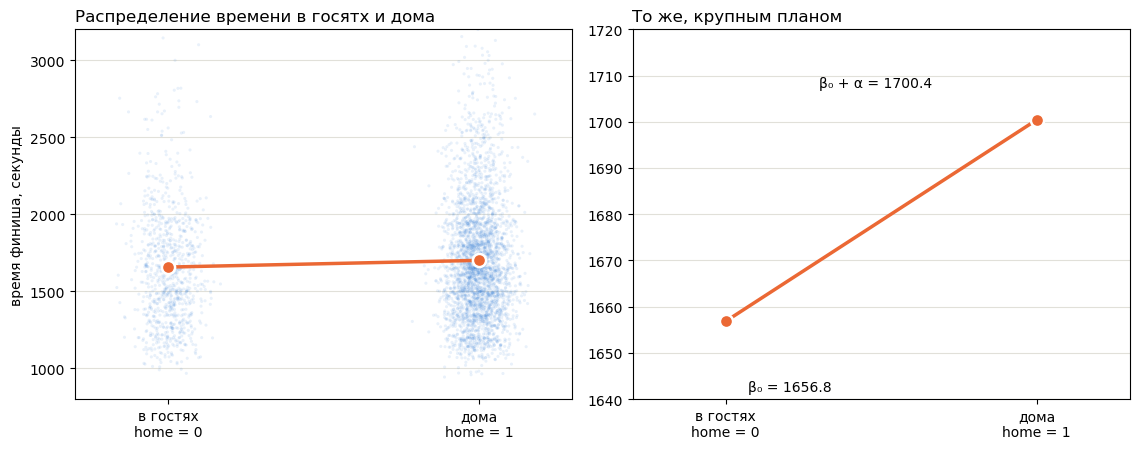

In [38]:
import numpy as np
import matplotlib.pyplot as plt

b0 = panel.loc[panel["home"] == 0, "total_time"].mean()
b1 = panel.loc[panel["home"] == 1, "total_time"].mean()

rng = np.random.default_rng(0)
s = panel.sample(4000, random_state=1)
x = s["home"] + rng.normal(0, 0.055, len(s))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))

for a in ax:
    a.plot([0, 1], [b0, b1], color="#eb6834", lw=2.5, zorder=5)
    a.scatter([0, 1], [b0, b1], s=90, color="#eb6834", zorder=6,
              edgecolors="white", linewidths=1.8)
    a.set_xticks([0, 1])
    a.set_xticklabels(["в гостях\nhome = 0", "дома\nhome = 1"])
    a.set_xlim(-0.3, 1.3)
    a.grid(axis="y", color="#e1e0d9", lw=0.8)
    a.set_axisbelow(True)

ax[0].scatter(x, s["total_time"], s=5, alpha=0.10, color="#2a78d6",
              edgecolors="none", zorder=1)
ax[0].set_ylim(800, 3200)
ax[0].set_ylabel("время финиша, секунды")
ax[0].set_title("Распределение времени в госятх и дома", loc="left")

ax[1].set_ylim(1640, 1720)
ax[1].set_title("То же, крупным планом", loc="left")
ax[1].annotate(f"β₀ = {b0:.1f}", (0, b0), xytext=(0.07, b0 - 15))
ax[1].annotate(f"β₀ + α = {b1:.1f}", (1, b1), xytext=(0.30, b1 + 7))

plt.tight_layout()
plt.show()

Проверяем, дает ли месяц искажение результатов:

Видно, что зимние месяцы медленнее летних. 
Видно, что летом доля домашних забегов меньше.

In [39]:
panel["month"] = panel["date"].dt.month

panel.groupby("month").agg(
    n=("total_time", "size"),
    mean_time=("total_time", "mean"),
    share_home=("home", "mean"),
).round(3)

,n,mean_time,share_home
month,,,
1,3163,1752.790,0.842
2,3146,1764.608,0.744
3,3659,1711.058,0.801
4,3265,1664.387,0.742
5,3443,1654.486,0.751
6,3412,1674.533,0.753
7,3492,1682.432,0.718
8,4272,1666.534,0.715
9,3548,1667.834,0.762


In [40]:
CL = {"CRV1": "event_id"}
FE = "| athlete_id + activity_id"

m1 = pf.feols("total_time ~ home", data=panel, vcov=CL)  #без эффектов
m2 = pf.feols("total_time ~ home | month", data=panel, vcov=CL) # эффект месяца 
m3 = pf.feols("total_time ~ home | athlete_id", data=panel, vcov=CL) # эффект резултатов конкретного атлета
m4 = pf.feols("total_time ~ home | athlete_id + event_id", data=panel, vcov=CL) # эффект конкретного атлета и локации
m5 = pf.feols("total_time ~ home | athlete_id + activity_id", data=panel, vcov=CL) # эффект конкретного атлета и активности
m6 = pf.feols("total_time ~ home | event_id", data=panel, vcov=CL) # эффект конкретной локации
m7 = pf.feols("total_time ~ home | activity_id", data=panel, vcov=CL) # эффект конкретного события
m8 = pf.feols("total_time ~ home | month + athlete_id", data=panel, vcov=CL) # эффект месяца и конкретного атлета



pf.etable([m1, m2, m3, m4, m5, m6, m7, m8])

/opt/anaconda3/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 464 singleton fixed effect(s) dropped from the model.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/pyfixest/estimation/formula/model_matrix.py:151: UserWarning: 461 singleton fixed effect(s) dropped from the model.
  warnings.warn(


GT(_tbl_data=  __index_level_0__ __index_level_1__                          0  \
0              coef              home       43.578 <br> (33.636)   
1              coef         Intercept  1656.845*** <br> (21.495)   
2                fe       activity_id                          -   
3                fe        athlete_id                          -   
4                fe          event_id                          -   
5                fe             month                          -   
6             stats      Observations                     39,883   
7             stats                R²                      0.002   

                      1                     2                       3  \
0  40.859 <br> (31.628)  29.959 <br> (17.643)  43.641*** <br> (7.456)   
1                                                                       
2                     -                     -                       -   
3                     -                     x                       -   
4                     -                     -                       -   
5                     x                     -                       -   
6                39,883                39,883                  39,883   
7                 0.011                 0.587                   0.591   

                        4                     5                     6  \
0  36.986*** <br> (5.737)  77.390 <br> (38.899)  56.008 <br> (32.072)   
1                                                                       
2                       -                     -                     x   
3                       -                     -                     -   
4                       -                     x                     -   
5                       -                     -                     -   
6                  39,419                39,883                39,422   
7                   0.651                 0.025                 0.123   

                      7  
0  24.633 <br> (17.269)  
1                        
2                     -  
3                     -  
4                     -  
5                     -  
6                39,883  
7                 0.597  , _body=<great_tables._gt_data.Body object at 0x16e21a630>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align=None, column_width=None, stub_level=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__index_level_1__', column_align='center', column_width=None, stub_level=0), ColInfo(var='0', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(1)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='1', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(2)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='2', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(3)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='3', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(4)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='4', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(5)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='5', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(6)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='6', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(7)'), column_align='center', column_width=None, stub_level=None), ColInfo(var='7', type=<ColInfoTypeEnum.default: 1>, column_label=Html(text='(8)'), column_align='center', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x16e3cf2c0>, _spanners=Spanners([SpannerInfo(spanner_id='total_time', spanner_level=1, spanner_label=Html(text='total_time'), spanner_units=None, spanner_pattern=None, vars=['0', '1', '2', '3', '4', '5', '6', '7'], built=None)]), _heading=H